<a href="https://colab.research.google.com/github/bvsvntv/ai-ml-learning/blob/main/notebooks/lang-graph/in_memmory_persistence.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -U langchain-openai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 587.1/587.1 kB 4.6 MB/s  0:00:00
  Attempting uninstall: langchain-core
    Found existing installation: langchain-core 1.7.4
    Uninstalling langchain-core-1.7.4:
      Successfully uninstalled langchain-core-1.7.4
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [langchain-openai]


In [2]:
from google.colab import userdata
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from langchain_openai import ChatOpenAI
from IPython.display import Image
from langgraph.checkpoint.memory import InMemorySaver
from pprint import pprint

In [3]:
api_key = userdata.get("OPENAI_API_KEY")
llm = ChatOpenAI(api_key=api_key, model="gpt-6-luna")

In [4]:
# state
class JokeState:
  topic: str
  joke: str
  explanation: str

In [5]:
def generate_joke(state: JokeState):
  prompt = f"Generate a joke on topic: {state["topic"]}"
  response = llm.invoke(prompt).content

  return {"joke": response}

In [6]:
def generate_explanation(state: JokeState):
  prompt = f"Write an explanation for a joke: {state["joke"]}"
  response = llm.invoke(prompt).content

  return {"explanation": response}

In [7]:
graph = StateGraph(JokeState)

graph.add_node("generate_joke", generate_joke)
graph.add_node("generate_explanation", generate_explanation)

graph.add_edge(START, "generate_joke")
graph.add_edge("generate_joke", "generate_explanation")
graph.add_edge("generate_explanation", END)

# checkpointer
checkpointer = InMemorySaver()

workflow = graph.compile(checkpointer=checkpointer)

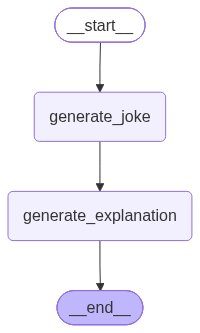

In [8]:
# view graph
Image(workflow.get_graph().draw_mermaid_png())

In [9]:
config1 = {"configurable": {"thread_id": 1}}
workflow.invoke({"topic": "momo"}, config=config1)

{'topic': 'momo',
 'joke': 'Why did the momo go to therapy? It had too much filling inside.',
 'explanation': 'The joke plays on the word “filling.” A momo is stuffed with filling, but “having too much inside” also suggests carrying too many emotions or problems—so it goes to therapy.'}

In [10]:
workflow.get_state(config1)

StateSnapshot(values={'topic': 'momo', 'joke': 'Why did the momo go to therapy? It had too much filling inside.', 'explanation': 'The joke plays on the word “filling.” A momo is stuffed with filling, but “having too much inside” also suggests carrying too many emotions or problems—so it goes to therapy.'}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1de893-3b88-68a9-8002-9349920fbd97'}}, metadata={'source': 'loop', 'step': 2, 'parents': {}}, created_at='2026-11-12T11:07:08.481303+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1de893-2a46-6694-8001-ff9c4ba7f5e4'}}, tasks=(), interrupts=())

In [11]:
pprint(list(workflow.get_state_history(config1)))

[StateSnapshot(values={'topic': 'momo', 'joke': 'Why did the momo go to therapy? It had too much filling inside.', 'explanation': 'The joke plays on the word “filling.” A momo is stuffed with filling, but “having too much inside” also suggests carrying too many emotions or problems—so it goes to therapy.'}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1de893-3b88-68a9-8002-9349920fbd97'}}, metadata={'source': 'loop', 'step': 2, 'parents': {}}, created_at='2026-11-12T11:07:08.481303+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1de893-2a46-6694-8001-ff9c4ba7f5e4'}}, tasks=(), interrupts=()),
 StateSnapshot(values={'topic': 'momo', 'joke': 'Why did the momo go to therapy? It had too much filling inside.'}, next=('generate_explanation',), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1de893-2a46-6694-8001-ff9c4ba7f5e4'}}, metadata={'source': 'loop', 's

In [12]:
config2 = {"configurable": {"thread_id": 2}}
workflow.invoke({"topic": "PUBG"}, config=config2)

{'topic': 'PUBG',
 'joke': 'Why did the PUBG player bring a frying pan to the job interview? He wanted to make sure he had a backup plan.',
 'explanation': 'In PUBG, the frying pan is a useful backup weapon—and can even block bullets. The joke plays on “backup plan”: the player literally brought a pan as a backup.'}

In [13]:
workflow.get_state(config2)

StateSnapshot(values={'topic': 'PUBG', 'joke': 'Why did the PUBG player bring a frying pan to the job interview? He wanted to make sure he had a backup plan.', 'explanation': 'In PUBG, the frying pan is a useful backup weapon—and can even block bullets. The joke plays on “backup plan”: the player literally brought a pan as a backup.'}, next=(), config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1de893-6843-6cfe-8002-68aec2aa488e'}}, metadata={'source': 'loop', 'step': 2, 'parents': {}}, created_at='2026-11-12T11:07:13.171754+00:00', parent_config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1de893-55a6-6cce-8001-d37c18cd2041'}}, tasks=(), interrupts=())

In [14]:
pprint(list(workflow.get_state_history(config=config2)))

[StateSnapshot(values={'topic': 'PUBG', 'joke': 'Why did the PUBG player bring a frying pan to the job interview? He wanted to make sure he had a backup plan.', 'explanation': 'In PUBG, the frying pan is a useful backup weapon—and can even block bullets. The joke plays on “backup plan”: the player literally brought a pan as a backup.'}, next=(), config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1de893-6843-6cfe-8002-68aec2aa488e'}}, metadata={'source': 'loop', 'step': 2, 'parents': {}}, created_at='2026-11-12T11:07:13.171754+00:00', parent_config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1de893-55a6-6cce-8001-d37c18cd2041'}}, tasks=(), interrupts=()),
 StateSnapshot(values={'topic': 'PUBG', 'joke': 'Why did the PUBG player bring a frying pan to the job interview? He wanted to make sure he had a backup plan.'}, next=('generate_explanation',), config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_i

### Time travel

`checkpoint_id` lets you select a previous workflow state, inspect it, optionally modify it, and continue execution from that point.

In [16]:
workflow.get_state(config={"configurable": {"thread_id": 2, "checkpoint_id": "1f1de893-3c31-637b-8000-310dc76f6991"}})

StateSnapshot(values={'topic': 'PUBG'}, next=('generate_joke',), config={'configurable': {'thread_id': '2', 'checkpoint_id': '1f1de893-3c31-637b-8000-310dc76f6991'}}, metadata={'source': 'loop', 'step': 0, 'parents': {}}, created_at='2026-11-12T11:07:08.550414+00:00', parent_config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1de893-3c2d-6734-bfff-59eb674ad1de'}}, tasks=(PregelTask(id='3a2e8abd-81b7-a21a-9d97-4d938554091d', name='generate_joke', path=('__pregel_pull', 'generate_joke'), error=None, interrupts=(), state=None, result={'joke': 'Why did the PUBG player bring a frying pan to the job interview? He wanted to make sure he had a backup plan.'}),), interrupts=())

In [17]:
workflow.invoke(None, config={"configurable": {"thread_id": 2, "checkpoint_id": "1f1de893-3c31-637b-8000-310dc76f6991"}})

{'topic': 'PUBG',
 'joke': 'Why did the PUBG player bring a ladder to the match? To reach the top of the leaderboard!',
 'explanation': 'The joke plays on “reaching the top”: a ladder helps you climb to a high place, while a PUBG player wants to climb to the top of the leaderboard by ranking first.'}

In [18]:
pprint(list(workflow.get_state_history(config=config2)))

[StateSnapshot(values={'topic': 'PUBG', 'joke': 'Why did the PUBG player bring a ladder to the match? To reach the top of the leaderboard!', 'explanation': 'The joke plays on “reaching the top”: a ladder helps you climb to a high place, while a PUBG player wants to climb to the top of the leaderboard by ranking first.'}, next=(), config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1de8a3-ba94-6f00-8003-f04206b02fb7'}}, metadata={'source': 'loop', 'step': 3, 'parents': {}}, created_at='2026-11-12T11:14:31.300030+00:00', parent_config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1de8a3-9596-6292-8002-8d33e9182e5a'}}, tasks=(), interrupts=()),
 StateSnapshot(values={'topic': 'PUBG', 'joke': 'Why did the PUBG player bring a ladder to the match? To reach the top of the leaderboard!'}, next=('generate_explanation',), config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1de8a3-9596-6292-8002-8d33e91

### Update State
Update state at particular checkpoint.

- creates a new checkpoint rather than modifying the old checkpoint directly.

In [22]:
workflow.update_state(config={"configurable": {"thread_id": 2, "checkpoint_id": "1f1de893-3c31-637b-8000-310dc76f6991", "checkpoint_ns": ""}}, values={"topic" : "fornite"})

{'configurable': {'thread_id': '2',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1de8c3-a748-6506-8001-b3700841e6c1'}}

In [24]:
pprint(list(workflow.get_state_history(config=config2)))

[StateSnapshot(values={'topic': 'fornite'}, next=('generate_joke',), config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1de8c3-a748-6506-8001-b3700841e6c1'}}, metadata={'source': 'update', 'step': 1, 'parents': {}}, created_at='2026-11-12T11:28:48.269824+00:00', parent_config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1de893-3c31-637b-8000-310dc76f6991'}}, tasks=(PregelTask(id='55162ccd-00bd-c4f9-19b1-6935c8ac3612', name='generate_joke', path=('__pregel_pull', 'generate_joke'), error=None, interrupts=(), state=None, result=None),), interrupts=()),
 StateSnapshot(values={'topic': 'PUBG', 'joke': 'Why did the PUBG player bring a ladder to the match? To reach the top of the leaderboard!', 'explanation': 'The joke plays on “reaching the top”: a ladder helps you climb to a high place, while a PUBG player wants to climb to the top of the leaderboard by ranking first.'}, next=(), config={'configurable': {'thread_id': '2', 'che

In [26]:
workflow.invoke(None, config={"configurable": {"thread_id": 2, "checkpoint_id": "1f1de8c3-a748-6506-8001-b3700841e6c1"}})

{'topic': 'fornite',
 'joke': 'Why did the Fortnite player bring a ladder to the match? To reach the next level!',
 'explanation': 'The joke plays on the double meaning of “level”: in Fortnite, players progress to the next game level, while a ladder helps someone climb to a higher physical level.'}

In [27]:
pprint(list(workflow.get_state_history(config=config2)))

[StateSnapshot(values={'topic': 'fornite', 'joke': 'Why did the Fortnite player bring a ladder to the match? To reach the next level!', 'explanation': 'The joke plays on the double meaning of “level”: in Fortnite, players progress to the next game level, while a ladder helps someone climb to a higher physical level.'}, next=(), config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1de8ca-ffb6-67f0-8004-3186bc674627'}}, metadata={'source': 'loop', 'step': 4, 'parents': {}}, created_at='2026-11-12T11:32:05.447234+00:00', parent_config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1de8ca-eb26-6925-8003-d550334d2429'}}, tasks=(), interrupts=()),
 StateSnapshot(values={'topic': 'fornite', 'joke': 'Why did the Fortnite player bring a ladder to the match? To reach the next level!'}, next=('generate_explanation',), config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1de8ca-eb26-6925-8003-d550334d2429'}